# Reglas de calidad de datos: detectar, medir y vigilar con rigor estadístico

**Perfil:** Liderazgo de datos y gobierno  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Un reporte de calidad que dice "98 % de cumplimiento" ¿qué tan fiable es? Las reglas pueden **fallar en detectar** (recall), **acusar de más** (precisión) y su indicador puede **moverse por azar**. ¿Qué tan bien detectan las reglas problemas inyectados con verdad conocida? ¿Cuántas filas hay que auditar para estimar la tasa de error? ¿Cuándo una subida del indicador es una señal y cuándo ruido?

## Recorrido

1. Tabla de clientes sintética con **problemas inyectados y registrados** (oráculo): nulos, llaves repetidas, duplicados *borrosos*, rangos, catálogos, incoherencias entre campos, obsolescencia.
2. Un **motor de reglas** que devuelve máscaras por fila y el reporte de cumplimiento.
3. **Precisión y recall** de cada regla contra el oráculo; falsos positivos *naturales* y cómo se corrigen con reglas condicionales.
4. **Duplicados borrosos:** por qué la regla de llave exacta no basta.
5. **Auditoría por muestreo:** intervalos de Wilson, cobertura simulada y tamaño de muestra.
6. **Monitoreo en el tiempo:** gráfico p, EWMA, longitud media de corrida (ARL) y retraso de detección.
7. Índice agregado y su trampa. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
import unicodedata, re
from scipy import stats

## 2. Tabla de clientes con problemas inyectados

20.000 clientes con `cliente_id`, `nombre`, `fecha_nac`, `edad`, `ingreso`, `ciudad`, `estado_laboral`, `fecha_alta`, `fecha_actualiz`. Se inyectan problemas **conocidos** (guardados en `oraculo`) y además hay un fenómeno **legítimo** que una regla ingenua marcaría mal: los estudiantes y jubilados sin ingreso (ingreso 0).

| problema | tasa inyectada |
|---|---|
| `edad` nula | 3,0 % |
| `cliente_id` repetido (se marcan las **dos** filas del par) | 0,5 % de pares = 1,0 % de filas |
| duplicado *borroso* (mismo cliente, nombre/ciudad escritos distinto, **otro** id) | 1,0 % |
| edad fuera de 18–100 | 1,0 % |
| ingreso negativo | 0,8 % |
| ciudad fuera del catálogo (error tipográfico) | 2,0 % |
| `edad` inconsistente con `fecha_nac` | 1,5 % |
| `fecha_actualiz` más de 60 días atrás | 5,0 % |

In [2]:
HOY = pd.Timestamp("2026-06-30")
CIUDADES = ["Bogota", "Medellin", "Cali", "Barranquilla", "Cartagena", "Bucaramanga", "Pereira", "Manizales", "Cucuta", "Ibague"]
NOMBRES = ["Maria", "Juan", "Carlos", "Ana", "Luis", "Laura", "Andres", "Camila", "Jose", "Paula", "Diego", "Sofia"]
APELLIDOS = ["Gomez", "Rodriguez", "Martinez", "Lopez", "Garcia", "Perez", "Sanchez", "Ramirez", "Torres", "Diaz", "Castro", "Ortiz"]

def generar(n=20_000, seed=SEED):
    rg = np.random.default_rng(seed)
    nac = HOY - pd.to_timedelta(rg.integers(int(18.6 * 365.25), 85 * 365, n), unit="D")
    df = pd.DataFrame({"cliente_id": np.arange(1, n + 1),
                       "nombre": [f"{rg.choice(NOMBRES)} {rg.choice(APELLIDOS)} {rg.choice(APELLIDOS)}" for _ in range(n)],
                       "fecha_nac": nac, "ciudad": rg.choice(CIUDADES, n),
                       "estado_laboral": rg.choice(["empleado", "independiente", "estudiante", "jubilado"], n, p=[.55, .25, .10, .10])})
    df["edad"] = ((HOY - df.fecha_nac).dt.days // 365.25).astype(float)
    ing = np.exp(rg.normal(15.0, 0.6, n)); df["ingreso"] = np.where(df.estado_laboral.isin(["estudiante", "jubilado"]) & (rg.random(n) < 0.6), 0.0, ing)
    df["fecha_alta"] = HOY - pd.to_timedelta(rg.integers(100, 2000, n), unit="D")
    df["fecha_actualiz"] = HOY - pd.to_timedelta(rg.integers(0, 55, n), unit="D")
    orac = pd.DataFrame(False, index=df.index, columns=["edad_nula", "id_repetido", "dup_borroso", "edad_rango", "ingreso_neg", "ciudad_fuera", "edad_incoh", "obsoleto"])
    libres = np.ones(n, bool)
    def elegir(tasa, elegible=None):
        # filas DISJUNTAS entre tipos de defecto, para que cada celda tenga a lo sumo una etiqueta del oraculo
        pool = np.flatnonzero(libres if elegible is None else libres & elegible); sel = rg.choice(pool, int(n * tasa), replace=False)
        libres[sel] = False; m = np.zeros(n, bool); m[sel] = True; return m
    m = elegir(0.015, (df.edad >= 28).values); df.loc[m, "edad"] = df.loc[m, "edad"] + rg.choice([-9, -6, 5, 8], m.sum()); orac["edad_incoh"] = m
    m = elegir(0.010); df.loc[m, "edad"] = rg.choice([5.0, 12.0, 120.0, 150.0], m.sum()); orac["edad_rango"] = m
    m = elegir(0.030); df.loc[m, "edad"] = np.nan; orac["edad_nula"] = m
    m = elegir(0.008, (df.ingreso > 0).values); df.loc[m, "ingreso"] = -np.abs(df.loc[m, "ingreso"]); orac["ingreso_neg"] = m
    m = elegir(0.020); df.loc[m, "ciudad"] = [c[:-1] + "x" for c in df.loc[m, "ciudad"]]; orac["ciudad_fuera"] = m
    m = elegir(0.050); df.loc[m, "fecha_actualiz"] = HOY - pd.to_timedelta(rg.integers(61, 400, m.sum()), unit="D"); orac["obsoleto"] = m
    # llave repetida: el registro copia el cliente_id de otro
    idx = rg.choice(np.arange(0, n, 2), int(n * 0.005), replace=False); df.loc[idx, "cliente_id"] = df.loc[idx + 1, "cliente_id"].values      # la fila par copia el id de su vecina impar
    orac.loc[idx, "id_repetido"] = True; orac.loc[idx + 1, "id_repetido"] = True                                                              # ambas filas del par comparten el defecto
    # duplicado borroso: copia de otro cliente con nombre/ciudad escritos distinto y NUEVO id
    src = rg.choice(n, int(n * 0.010), replace=False); cop = df.iloc[src].copy()
    cop["nombre"] = [x.upper().replace("A", "Á", 1) if rg.random() < .5 else x.lower() for x in cop.nombre]
    cop["cliente_id"] = np.arange(n + 1, n + 1 + len(cop)); orac_c = orac.iloc[src].copy(); orac_c["id_repetido"] = False; orac_c["dup_borroso"] = True      # la copia hereda los defectos de su origen
    cop.index = np.arange(n, n + len(cop)); orac_c.index = cop.index
    return pd.concat([df, cop]), pd.concat([orac, orac_c])

df, orac = generar()
print(f"{len(df):,} filas, {orac.any(axis=1).sum():,} con algun problema inyectado ({orac.any(axis=1).mean():.1%})")
print((orac.mean() * 100).round(2).to_string())
print(f"\nIngreso 0 'legitimo' (estudiante/jubilado): {(df.ingreso == 0).sum():,} filas ({(df.ingreso == 0).mean():.1%})")

20,200 filas, 3,036 con algun problema inyectado (15.0%)
edad_nula      3.0000
id_repetido    0.9900
dup_borroso    0.9900
edad_rango     1.0000
ingreso_neg    0.8000
ciudad_fuera   1.9900
edad_incoh     1.5000
obsoleto       5.0000

Ingreso 0 'legitimo' (estudiante/jubilado): 2,413 filas (11.9%)


## 3. Motor de reglas y reporte

Cada regla devuelve una máscara de filas **que fallan**. El reporte da el cumplimiento y las filas fallidas. Las reglas se escriben primero de forma **ingenua** (la que haría un analista apurado) y luego se comparan con el oráculo.

In [3]:
REGLAS = {
    "completitud_edad": lambda d: d.edad.isna(),
    "unicidad_cliente_id": lambda d: d.cliente_id.duplicated(keep=False),                 # marca ambas copias
    "rango_edad_18_100": lambda d: d.edad.notna() & ((d.edad < 18) | (d.edad > 100)),
    "ingreso_positivo": lambda d: d.ingreso <= 0,                                         # ingenua: marca los ceros legitimos
    "ciudad_en_catalogo": lambda d: ~d.ciudad.isin(CIUDADES),
    "edad_coherente_con_nacimiento": lambda d: d.edad.notna() & ((d.edad - (HOY - d.fecha_nac).dt.days // 365.25).abs() > 1),
    "actualizado_60_dias": lambda d: (HOY - d.fecha_actualiz).dt.days > 60,
}
MAPA = {"completitud_edad": "edad_nula", "unicidad_cliente_id": "id_repetido", "rango_edad_18_100": "edad_rango", "ingreso_positivo": "ingreso_neg",
        "ciudad_en_catalogo": "ciudad_fuera", "edad_coherente_con_nacimiento": "edad_incoh", "actualizado_60_dias": "obsoleto"}

def ejecutar(d, reglas):
    return pd.DataFrame({k: np.asarray(f(d), dtype=bool) for k, f in reglas.items()}, index=d.index)

def reporte(fallos, orac):
    filas = []
    for k in fallos.columns:
        pred, real = fallos[k], orac[MAPA[k]]
        tp = (pred & real).sum(); fp = (pred & ~real).sum(); fn = (~pred & real).sum()
        otros = orac.drop(columns=MAPA[k]).any(axis=1)                      # filas con OTRO defecto inyectado
        casc = (pred & ~real & otros).sum()
        filas.append({"regla": k, "cumplimiento": 1 - pred.mean(), "filas_fallidas": int(pred.sum()), "inyectadas": int(real.sum()), "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1), "falsos_pos": int(fp), "en_cascada": int(casc), "falsos_pos_puros": int(fp - casc), "falsos_neg": int(fn)})
    return pd.DataFrame(filas).set_index("regla")

fallos0 = ejecutar(df, REGLAS); rep0 = reporte(fallos0, orac); rep0.round(3)

,cumplimiento,filas_fallidas,inyectadas,precision,recall,falsos_pos,en_cascada,falsos_pos_puros,falsos_neg
regla,,,,,,,,,
completitud_edad,0.9700,607,607,1.0000,1.0000,0,0,0,0
unicidad_cliente_id,0.9900,200,200,1.0000,1.0000,0,0,0,0
rango_edad_18_100,0.9900,202,202,1.0000,1.0000,0,0,0,0
ingreso_positivo,0.8730,2574,161,0.0630,1.0000,2413,339,2074,0
ciudad_en_catalogo,0.9800,402,402,1.0000,1.0000,0,0,0,0
edad_coherente_con_nacimiento,0.9750,505,303,0.6000,1.0000,202,202,0,0
actualizado_60_dias,0.9500,1009,1009,1.0000,1.0000,0,0,0,0


In [4]:
print("Lectura:")
print(f"  Las reglas de rango, nulos, catalogo y obsolescencia tienen precision {rep0.loc[['completitud_edad', 'rango_edad_18_100', 'ciudad_en_catalogo', 'actualizado_60_dias'], 'precision'].min():.2f}-1.00 y recall ~1.00: se cumple lo que prometen.")
print(f"  'edad_coherente_con_nacimiento' tiene precision {rep0.loc['edad_coherente_con_nacimiento', 'precision']:.2f} frente a su propia etiqueta, pero {int(rep0.loc['edad_coherente_con_nacimiento', 'en_cascada'])} de sus 'falsos positivos' son filas con una edad fuera de rango: el defecto es REAL y dispara dos reglas (cascada); falsos positivos puros: {int(rep0.loc['edad_coherente_con_nacimiento', 'falsos_pos_puros'])}. Un tablero que suma reglas cuenta dos veces el mismo problema.")
print(f"  'ingreso_positivo' reporta {rep0.loc['ingreso_positivo', 'filas_fallidas']:,} fallos pero solo {rep0.loc['ingreso_positivo', 'inyectadas']:,} son errores: precision {rep0.loc['ingreso_positivo', 'precision']:.2f}. El resto son estudiantes/jubilados con ingreso 0 legitimo.")
print(f"  Los duplicados borrosos NO los detecta ninguna regla: {int(orac['dup_borroso'].sum()):,} filas pasan inadvertidas ({orac['dup_borroso'].mean():.1%} de la tabla).")

Lectura:
  Las reglas de rango, nulos, catalogo y obsolescencia tienen precision 1.00-1.00 y recall ~1.00: se cumple lo que prometen.
  'edad_coherente_con_nacimiento' tiene precision 0.60 frente a su propia etiqueta, pero 202 de sus 'falsos positivos' son filas con una edad fuera de rango: el defecto es REAL y dispara dos reglas (cascada); falsos positivos puros: 0. Un tablero que suma reglas cuenta dos veces el mismo problema.
  'ingreso_positivo' reporta 2,574 fallos pero solo 161 son errores: precision 0.06. El resto son estudiantes/jubilados con ingreso 0 legitimo.
  Los duplicados borrosos NO los detecta ninguna regla: 200 filas pasan inadvertidas (1.0% de la tabla).


## 4. Corrección de falsos positivos y de la unicidad

1. **Regla condicional:** el ingreso debe ser positivo *salvo* para estudiantes y jubilados, donde basta que sea no negativo.

La regla de unicidad con `duplicated(keep=False)` marca **ambas** filas del par, que es lo correcto: el oráculo etiqueta las dos como parte del defecto, y las llaves afectadas son la mitad de las filas marcadas. Se recalculan precisión y recall con la regla de ingreso corregida.

In [5]:
REGLAS2 = dict(REGLAS)
REGLAS2["ingreso_positivo"] = lambda d: np.where(d.estado_laboral.isin(["estudiante", "jubilado"]), d.ingreso < 0, d.ingreso <= 0)
fallos1 = ejecutar(df, REGLAS2); rep1 = reporte(fallos1, orac)
comp = pd.concat({"antes": rep0[["precision", "recall", "falsos_pos"]], "despues": rep1[["precision", "recall", "falsos_pos"]]}, axis=1).loc[["ingreso_positivo"]]
comp.round(3)

antes                     despues                  
                 precision recall falsos_pos precision recall falsos_pos
regla                                                                   
ingreso_positivo    0.0630 1.0000       2413    1.0000 1.0000          0

In [6]:
print("Lectura:")
print(f"  'ingreso_positivo': precision {rep0.loc['ingreso_positivo', 'precision']:.2f} -> {rep1.loc['ingreso_positivo', 'precision']:.2f} con recall {rep1.loc['ingreso_positivo', 'recall']:.2f}: la regla condicional elimina los {int(rep0.loc['ingreso_positivo', 'falsos_pos']):,} falsos positivos.")
print(f"  'unicidad_cliente_id': precision {rep1.loc['unicidad_cliente_id', 'precision']:.2f} y recall {rep1.loc['unicidad_cliente_id', 'recall']:.2f}; {int(rep1.loc['unicidad_cliente_id', 'filas_fallidas'])} filas marcadas = {int(rep1.loc['unicidad_cliente_id', 'filas_fallidas']) // 2} llaves repetidas: al remediar se cuenta por llave, no por fila.")
print("  Moraleja: una regla sin contexto de negocio produce alertas que el equipo aprende a ignorar; medir la precision contra casos revisados es parte del gobierno de datos.")

Lectura:
  'ingreso_positivo': precision 0.06 -> 1.00 con recall 1.00: la regla condicional elimina los 2,413 falsos positivos.
  'unicidad_cliente_id': precision 1.00 y recall 1.00; 200 filas marcadas = 100 llaves repetidas: al remediar se cuenta por llave, no por fila.
  Moraleja: una regla sin contexto de negocio produce alertas que el equipo aprende a ignorar; medir la precision contra casos revisados es parte del gobierno de datos.


## 5. Duplicados borrosos

Se normaliza el nombre (minúsculas, sin tildes, sin signos) y se cruza con `fecha_nac` y `ciudad` normalizada. La **llave de bloqueo** `(nombre_norm, fecha_nac)` agrupa candidatos. Se mide el recall y la precisión frente al oráculo y se muestra el costo de un nombre demasiado laxo (solo apellido + fecha).

In [7]:
def norm(s): 
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower(); return re.sub(r"[^a-z ]", "", s).strip()

def dup_borroso(d, laxo=False):
    k = d.nombre.map(norm); 
    if laxo: k = k.str.split().str[-1]
    clave = k + "|" + d.fecha_nac.dt.strftime("%Y-%m-%d")
    return clave.duplicated(keep="first")

def medir(pred, real):
    tp = (pred & real).sum(); fp = (pred & ~real).sum(); fn = (~pred & real).sum(); return tp / max(tp + fp, 1), tp / max(tp + fn, 1), int(fp), int(fn)

filas = []
for nombre, pred in (("llave exacta (cliente_id)", df.cliente_id.duplicated(keep="first")), ("nombre normalizado + fecha_nac", dup_borroso(df)), ("solo apellido + fecha_nac", dup_borroso(df, laxo=True))):
    p, r, fp, fn = medir(pred.values, orac["dup_borroso"].values); filas.append({"estrategia": nombre, "precision": p, "recall": r, "falsos_pos": fp, "falsos_neg": fn})
db = pd.DataFrame(filas).set_index("estrategia"); db.round(3)

,precision,recall,falsos_pos,falsos_neg
estrategia,,,,
llave exacta (cliente_id),0.0000,0.0000,100,200
nombre normalizado + fecha_nac,0.9760,1.0000,5,0
solo apellido + fecha_nac,0.2250,1.0000,690,0


In [8]:
print("Lectura:")
print(f"  La llave exacta detecta {db.loc['llave exacta (cliente_id)', 'recall']:.0%} de los duplicados borrosos (nuevo id); nombre normalizado + fecha_nac detecta {db.loc['nombre normalizado + fecha_nac', 'recall']:.0%} con precision {db.loc['nombre normalizado + fecha_nac', 'precision']:.0%}.")
print(f"  Una clave laxa (solo apellido + fecha) mantiene el recall ({db.loc['solo apellido + fecha_nac', 'recall']:.0%}) pero su precision cae a {db.loc['solo apellido + fecha_nac', 'precision']:.2f}: {int(db.loc['solo apellido + fecha_nac', 'falsos_pos'])} falsos positivos para revisar. Una clave mas estricta cuesta menos que revisar cada coincidencia.")

Lectura:
  La llave exacta detecta 0% de los duplicados borrosos (nuevo id); nombre normalizado + fecha_nac detecta 100% con precision 98%.
  Una clave laxa (solo apellido + fecha) mantiene el recall (100%) pero su precision cae a 0.22: 690 falsos positivos para revisar. Una clave mas estricta cuesta menos que revisar cada coincidencia.


## 6. Auditoría por muestreo: ¿cuántas filas revisar?

Revisar todas las filas a mano es inviable. Se estima la **tasa de filas con algún error** con una muestra aleatoria de $n$ filas y un intervalo de **Wilson** (mejor que el normal cuando $p$ es pequeño). Se verifica la **cobertura** por simulación y el tamaño de muestra para un margen dado.

In [9]:
def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z ** 2 / n; c = (p + z ** 2 / (2 * n)) / den; h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den; return c - h, c + h

P_REAL = orac.any(axis=1).mean(); rg = np.random.default_rng(5); error = orac.any(axis=1).values
filas = []
for n in (100, 300, 1000, 3000):
    cub_w = cub_n = 0; anch = []
    for _ in range(2000):
        k = error[rg.choice(len(error), n, replace=False)].sum(); lo, hi = wilson(k, n); cub_w += lo <= P_REAL <= hi; anch.append(hi - lo)
        ph = k / n; se = np.sqrt(ph * (1 - ph) / n) if 0 < k < n else 0; cub_n += (ph - 1.96 * se <= P_REAL <= ph + 1.96 * se)
    filas.append({"n_muestra": n, "cobertura_wilson": cub_w / 2000, "cobertura_normal": cub_n / 2000, "ancho_medio": np.mean(anch)})
aud = pd.DataFrame(filas).set_index("n_muestra")
n_req = int(np.ceil(1.96 ** 2 * P_REAL * (1 - P_REAL) / 0.01 ** 2))
print(f"Tasa real de filas con algun error: {P_REAL:.2%}. Tamano de muestra para margen +-1 pp: {n_req:,}")
aud.round(4)

Tasa real de filas con algun error: 15.03%. Tamano de muestra para margen +-1 pp: 4,907


,cobertura_wilson,cobertura_normal,ancho_medio
n_muestra,,,
100,0.9535,0.9375,0.1389
300,0.9610,0.9460,0.0807
1000,0.9555,0.9570,0.0443
3000,0.9640,0.9620,0.0256


In [10]:
print("Lectura:")
print(f"  El intervalo de Wilson cubre ~{aud['cobertura_wilson'].mean():.0%} (objetivo 95%) en todos los tamanos; el normal con n=100 cubre {aud.loc[100, 'cobertura_normal']:.0%}.")
print(f"  Con 1.000 filas, el ancho medio es {aud.loc[1000, 'ancho_medio']:.1%}: se puede decir que ~{P_REAL:.0%} de las filas tiene algun error, +-{aud.loc[1000, 'ancho_medio'] / 2:.1%}.")
print(f"  Auditar {n_req:,} filas basta para estimar la tasa global con margen de 1 pp; estimar la tasa de UN tipo raro (0,5%) con la misma precision relativa exige muchas mas.")

Lectura:
  El intervalo de Wilson cubre ~96% (objetivo 95%) en todos los tamanos; el normal con n=100 cubre 94%.
  Con 1.000 filas, el ancho medio es 4.4%: se puede decir que ~15% de las filas tiene algun error, +-2.2%.
  Auditar 4,907 filas basta para estimar la tasa global con margen de 1 pp; estimar la tasa de UN tipo raro (0,5%) con la misma precision relativa exige muchas mas.


## 7. Monitoreo en el tiempo: ¿señal o ruido?

El cumplimiento diario de una regla fluctúa por azar. Se compara:

- **Gráfico p** con límites a $3\sigma$ calculados en un período base.
- **EWMA** ($\lambda=0{,}2$) con un multiplicador $L$ **calibrado por simulación** para que su ARL₀ iguale al del gráfico p (si no, la comparación de retrasos sería injusta: un EWMA con límites a $3\sigma$ tiene muchas menos falsas alarmas).

Se mide la **longitud media de corrida en control (ARL₀)** (cuántos lotes pasan hasta una falsa alarma) y el **retraso de detección** cuando la tasa de fallos sube de 2 % a 3 % (desplazamiento pequeño) y a 5 % (grande). Lotes de 2.000 filas.

In [11]:
N_LOTE, P0 = 2000, 0.02
sig = np.sqrt(P0 * (1 - P0) / N_LOTE)
LCS_P = P0 + 3 * sig
ALFA_P = stats.binom.sf(int(np.floor(LCS_P * N_LOTE)), N_LOTE, P0)              # probabilidad exacta de falsa alarma por lote
ARL0_P_EXACTO = 1 / ALFA_P
LAM = 0.2; sig_inf = sig * np.sqrt(LAM / (2 - LAM))

def longitudes(p_real, metodo, L, R, T, rg):
    x = rg.binomial(N_LOTE, p_real, (R, T)) / N_LOTE
    if metodo == "p":
        ex = x > LCS_P
    else:
        z = np.empty_like(x); z[:, 0] = LAM * x[:, 0] + (1 - LAM) * P0
        for t in range(1, T): z[:, t] = LAM * x[:, t] + (1 - LAM) * z[:, t - 1]
        ex = z > P0 + L * sig_inf
    return np.where(ex.any(axis=1), ex.argmax(axis=1) + 1, T)                    # censurado en T

# calibrar el multiplo L del EWMA para que su ARL0 iguale al del grafico p (comparacion justa)
rg = np.random.default_rng(3); R0, T0 = 1500, 6000
cal = {L: longitudes(P0, "ewma", L, R0, T0, np.random.default_rng(3)).mean() for L in (2.4, 2.5, 2.6, 2.7, 2.8)}
Ls = np.array(list(cal)); arls = np.array(list(cal.values()))
L_E = float(np.interp(np.log(ARL0_P_EXACTO), np.log(arls), Ls))
print(f"ARL0 exacto del grafico p (limite 3 sigma, binomial): {ARL0_P_EXACTO:.0f} lotes")
print("ARL0 del EWMA segun L:", {k: round(v) for k, v in cal.items()}, f"-> L calibrado = {L_E:.2f}")

R, T = 1500, 6000
filas = []
for k, (p_real, etiqueta) in enumerate(((0.02, "en control (2%)"), (0.025, "desplazamiento 2.5%"), (0.03, "desplazamiento 3%"), (0.05, "desplazamiento 5%"))):
    fila = {"escenario": etiqueta}
    for met in ("p", "ewma"):
        rl = longitudes(p_real, met, L_E, R, T, np.random.default_rng(100 + k)); fila[f"ARL_{met}"] = rl.mean(); fila[f"mediana_{met}"] = np.median(rl)
    filas.append(fila)
arl = pd.DataFrame(filas).set_index("escenario"); arl.round(1)

ARL0 exacto del grafico p (limite 3 sigma, binomial): 380 lotes
ARL0 del EWMA segun L: {2.4: 195, 2.5: 240, 2.6: 307, 2.7: 400, 2.8: 512} -> L calibrado = 2.68


,ARL_p,mediana_p,ARL_ewma,mediana_ewma
escenario,,,,
en control (2%),377.2000,264.0000,370.3000,256.0000
desplazamiento 2.5%,8.8000,6.0000,4.4000,4.0000
desplazamiento 3%,1.8000,1.0000,2.1000,2.0000
desplazamiento 5%,1.0000,1.0000,1.0000,1.0000


In [12]:
print("Lectura (lotes hasta la alarma):")
print(f"  En control, una alarma falsa llega en promedio cada {arl.loc['en control (2%)', 'ARL_p']:.0f} lotes con el grafico p (exacto: {ARL0_P_EXACTO:.0f}) y cada {arl.loc['en control (2%)', 'ARL_ewma']:.0f} con EWMA calibrado (L={L_E:.2f}): la comparacion es a igual tasa de falsas alarmas.")
print(f"  Con un deterioro grande (5%): p tarda {arl.loc['desplazamiento 5%', 'ARL_p']:.1f} lotes; EWMA {arl.loc['desplazamiento 5%', 'ARL_ewma']:.1f}.")
print(f"  A igual tasa de falsas alarmas el EWMA detecta el deterioro pequeno (2.5%) en {arl.loc['desplazamiento 2.5%', 'ARL_ewma']:.1f} lotes frente a {arl.loc['desplazamiento 2.5%', 'ARL_p']:.1f} del grafico p (la mitad); con 3% el grafico p ya es comparable ({arl.loc['desplazamiento 3%', 'ARL_p']:.1f} vs {arl.loc['desplazamiento 3%', 'ARL_ewma']:.1f}) y con 5% ambos alarman en el primer lote.")
print("  Es la ventaja conocida del EWMA: acumula evidencia de desplazamientos pequenos y sostenidos, que erosionan la calidad sin que nadie los note en un tablero diario.")

Lectura (lotes hasta la alarma):
  En control, una alarma falsa llega en promedio cada 377 lotes con el grafico p (exacto: 380) y cada 370 con EWMA calibrado (L=2.68): la comparacion es a igual tasa de falsas alarmas.
  Con un deterioro grande (5%): p tarda 1.0 lotes; EWMA 1.0.
  A igual tasa de falsas alarmas el EWMA detecta el deterioro pequeno (2.5%) en 4.4 lotes frente a 8.8 del grafico p (la mitad); con 3% el grafico p ya es comparable (1.8 vs 2.1) y con 5% ambos alarman en el primer lote.
  Es la ventaja conocida del EWMA: acumula evidencia de desplazamientos pequenos y sostenidos, que erosionan la calidad sin que nadie los note en un tablero diario.


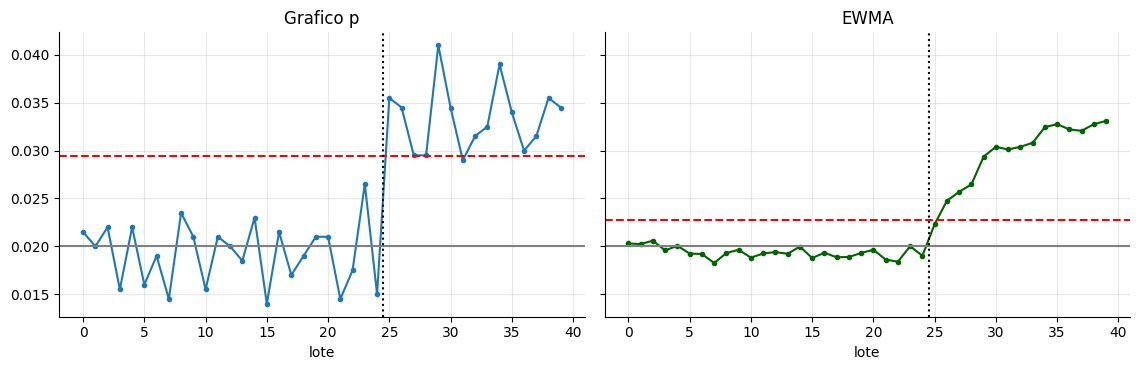

Primera alarma tras el cambio (lote 26): grafico p -> lote 26; EWMA -> lote 27


In [13]:
# una serie de ejemplo: 40 lotes, deterioro de 2% a 3.5% desde el lote 26
rg = np.random.default_rng(31); p_serie = np.r_[np.full(25, .02), np.full(15, .035)]
LCS_E = P0 + L_E * sig_inf; x = rg.binomial(N_LOTE, p_serie) / N_LOTE; z = np.empty_like(x); z[0] = LAM * x[0] + (1 - LAM) * P0
for i in range(1, len(x)): z[i] = LAM * x[i] + (1 - LAM) * z[i - 1]
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
ax[0].plot(x, "o-", ms=3); ax[0].axhline(LCS_P, c="r", ls="--"); ax[0].axhline(P0, c="gray"); ax[0].axvline(24.5, c="k", ls=":"); ax[0].set_title("Grafico p"); ax[0].set_xlabel("lote")
ax[1].plot(z, "o-", ms=3, c="darkgreen"); ax[1].axhline(LCS_E, c="r", ls="--"); ax[1].axhline(P0, c="gray"); ax[1].axvline(24.5, c="k", ls=":"); ax[1].set_title("EWMA"); ax[1].set_xlabel("lote")
plt.tight_layout(); plt.show()
a_p = int(np.argmax(x > LCS_P)) + 1 if (x > LCS_P).any() else None; a_e = int(np.argmax(z > LCS_E)) + 1 if (z > LCS_E).any() else None
print(f"Primera alarma tras el cambio (lote 26): grafico p -> lote {a_p}; EWMA -> lote {a_e}")

## 8. Índice agregado y su trampa

Se suele promediar el cumplimiento de todas las reglas en un único índice. Con 7 reglas el promedio simple da ~98 %, aunque una regla (obsolescencia) esté en 95 %. Se comparan el promedio simple, el **mínimo** y un índice ponderado por **severidad** (completitud e integridad pesan más que obsolescencia).

In [14]:
cump = 1 - fallos1.mean(); sev = pd.Series({"completitud_edad": 3, "unicidad_cliente_id": 5, "rango_edad_18_100": 3, "ingreso_positivo": 4, "ciudad_en_catalogo": 2, "edad_coherente_con_nacimiento": 3, "actualizado_60_dias": 1})
idx = pd.Series({"promedio_simple": cump.mean(), "minimo": cump.min(), "ponderado_severidad": np.average(cump, weights=sev), "fraccion_filas_100%_limpias": 1 - fallos1.any(axis=1).mean()})
print(cump.round(4).to_string()); print(); print(idx.round(4).to_string())

completitud_edad                0.9700
unicidad_cliente_id             0.9901
rango_edad_18_100               0.9900
ingreso_positivo                0.9920
ciudad_en_catalogo              0.9801
edad_coherente_con_nacimiento   0.9750
actualizado_60_dias             0.9500

promedio_simple               0.9782
minimo                        0.9500
ponderado_severidad           0.9826
fraccion_filas_100%_limpias   0.8584


In [15]:
print("Lectura:")
print(f"  El promedio simple da {idx['promedio_simple']:.1%} y suena casi perfecto, pero solo el {idx['fraccion_filas_100%_limpias']:.1%} de las filas pasa TODAS las reglas: los errores se reparten en filas distintas y se suman.")
print(f"  El minimo ({idx['minimo']:.1%}, regla '{cump.idxmin()}') es el indicador de gestion mas honesto; el ponderado ({idx['ponderado_severidad']:.1%}) depende de pesos que hay que justificar.")

Lectura:
  El promedio simple da 97.8% y suena casi perfecto, pero solo el 85.8% de las filas pasa TODAS las reglas: los errores se reparten en filas distintas y se suman.
  El minimo (95.0%, regla 'actualizado_60_dias') es el indicador de gestion mas honesto; el ponderado (98.3%) depende de pesos que hay que justificar.


## 9. Pruebas automáticas

In [16]:
# 9.1 el generador inyecta las tasas pedidas (oraculo)
exp = {"edad_nula": .03, "id_repetido": .01, "dup_borroso": .01, "edad_rango": .01, "ingreso_neg": .008, "ciudad_fuera": .02, "edad_incoh": .015, "obsoleto": .05}
for k, v in exp.items(): assert abs(orac.iloc[:20_000][k].sum() / 20_000 - v) < 1e-9 if k != "dup_borroso" else abs(orac[k].sum() / 20_000 - v) < 1e-9, k
assert len(df) == 20_200 and orac.iloc[20_000:]["dup_borroso"].all()      # las 200 copias heredan los defectos de su origen
# 9.2 reglas precisas con recall ~1 en las de contexto simple
for k in ("completitud_edad", "rango_edad_18_100", "ciudad_en_catalogo", "actualizado_60_dias"): assert rep0.loc[k, "recall"] > 0.99 and rep0.loc[k, "precision"] > 0.99, k
# cascada: la regla de coherencia dispara sobre las edades fuera de rango (defecto real), sin falsos positivos puros
assert rep0.loc["edad_coherente_con_nacimiento", "en_cascada"] >= 0.9 * orac["edad_rango"].sum() * (1 - 0.0) - 20 and rep0.loc["edad_coherente_con_nacimiento", "falsos_pos_puros"] == 0 and rep0.loc["edad_coherente_con_nacimiento", "recall"] > 0.99
# 9.3 regla ingenua de ingreso con muchos falsos positivos; la condicional los elimina
assert rep0.loc["ingreso_positivo", "precision"] < 0.20 and rep1.loc["ingreso_positivo", "precision"] > 0.95 and rep1.loc["ingreso_positivo", "recall"] > 0.99
# 9.4 unicidad: marca exactamente las dos filas de cada par
assert rep1.loc["unicidad_cliente_id", "precision"] > 0.99 and rep1.loc["unicidad_cliente_id", "recall"] > 0.99 and rep1.loc["unicidad_cliente_id", "filas_fallidas"] % 2 == 0
# 9.5 duplicados borrosos: la llave exacta no los ve; la normalizada si
assert db.loc["llave exacta (cliente_id)", "recall"] < 0.05 and db.loc["nombre normalizado + fecha_nac", "recall"] > 0.95 and db.loc["nombre normalizado + fecha_nac", "precision"] > 0.95
# 9.6 auditoria: Wilson cubre cerca de 95% y el normal con n pequeno no mejor
assert (aud["cobertura_wilson"].between(0.93, 0.97)).all() and aud["ancho_medio"].is_monotonic_decreasing
# 9.7 monitoreo: ARL en control grande, deterioro grande detectado rapido, EWMA mejor que p con desplazamiento pequeno
assert abs(arl.loc["en control (2%)", "ARL_p"] / ARL0_P_EXACTO - 1) < 0.15 and abs(arl.loc["en control (2%)", "ARL_ewma"] / ARL0_P_EXACTO - 1) < 0.25
assert arl.loc["desplazamiento 5%", "ARL_p"] < 3
assert arl.loc["desplazamiento 2.5%", "ARL_ewma"] < 0.75 * arl.loc["desplazamiento 2.5%", "ARL_p"]
assert arl.loc["desplazamiento 2.5%", "ARL_ewma"] < arl.loc["desplazamiento 2.5%", "ARL_p"]
# 9.8 el indice agregado engana: promedio alto, filas limpias bajas
assert idx["promedio_simple"] > 0.97 and idx["fraccion_filas_100%_limpias"] < 0.90 and idx["minimo"] < idx["promedio_simple"]
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Reglas simples | Nulos, rangos, catálogos y obsolescencia detectan lo que prometen con alta precisión y recall | Empezar por ellas y medir contra casos revisados |
| Falsos positivos | Una regla sin contexto (ingreso > 0) genera alertas que el equipo aprende a ignorar | Escribir reglas condicionales al negocio |
| Duplicados | La llave exacta no ve duplicados con otro id; la clave normalizada sí | Normalizar y bloquear por atributos estables |
| Auditoría | Una muestra de ~1.000 filas estima la tasa global con ±2 pp y ~5.000 con ±1 pp; Wilson cubre bien | Reportar intervalo, no solo el punto |
| Monitoreo | A igual tasa de falsas alarmas, el EWMA detecta los deterioros pequeños en la mitad de lotes; con deterioros grandes ambos alarman de inmediato | Usar EWMA para derivas lentas de calidad |
| Índice agregado | El promedio de cumplimientos oculta que pocas filas pasan todas las reglas | Reportar también el mínimo y las filas limpias |

**Límites que no deben ocultarse**

- Los problemas inyectados son independientes y de tasa fija; en datos reales se concentran por fuente y canal.
- El nombre se genera de pocas palabras: los homónimos y las colisiones de nombre + fecha son más raros aquí que en la realidad.
- El ARL de los gráficos supone lotes independientes y tasa estable en el período base.
- No hay evidencia de desempeño en datos reales; el notebook es un banco de pruebas del método.